# HW 2 – ML pipeline experiment with Random Forest
### Random Forest classification of the e1 neuron cluster from single-cell gene-expression data (scikit-learn)

&nbsp;

**Class:** CSC 659/859 – Fall 2026 (Prof. D. Petkovic)<br>
**Semester:** Fall 2026<br>
**Date:** October 17, 2026<br>
**Name:** Ryan Selvarajan<br>
**Email:** selvarajanryan@gmail.com

<div style="page-break-after: always;"></div>

In [1]:
# =============================================================================
# CSC 659/859 Fall 2026 - HW 2: ML pipeline experiment with Random Forest (RF)
# Author : Ryan Selvarajan
# Purpose: Classify e1 neuron-cluster samples (Label 1) vs. all other samples
#          (Label 0) from 608 gene-expression features with scikit-learn RF:
#          audit -> training/verification split -> RF training with OOB
#          (Method 1) and manual stratified 3-fold CV (Method 2) -> Gini feature
#          ranking -> run-time test on the 2 verification samples.
# =============================================================================
import json
import math

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix

%config InlineBackend.figure_formats = ["svg"]
pd.options.display.float_format = "{:.5f}".format   # all accuracy measures with 5 decimals

CSV_PATH = "Original training DB e1 cluster.csv"   # Original DB from Canvas
LABEL = "Label"                                    # 1 = e1 cluster, 0 = not e1
SEED = 42                                          # verification split, CV folds and every RF
NTREE_GRID = [500, 1000, 2000]                     # NTREE (n_estimators) values for the grid
N_FOLDS = 3
GROUND_TRUTH = ["TESPA1", "LINC00507", "SLC17A7", "KCNIP1"]   # e1 marker genes from [1]

## 2. Audit of Original database

In this section we describe where the data comes from, import it, summarize its statistics, and audit it item by item against the class audit checklist.

**Data source.** The data are real gene-expression measurements from the J. Craig Venter Institute (JCVI, La Jolla / San Diego, CA), described in Aevermann et al. 2018 [1]. Single nuclei were isolated from cortical layer 1 of the middle temporal gyrus (MTG) of a post-mortem human brain specimen, sorted, and RNA-sequenced (single-nucleus RNA-seq). Each row is one sample (one nucleus/cell). Each feature column is named after a gene, and its value is that gene's expression level (how much of the gene's mRNA was measured). [1] grouped the samples into 16 cell-type clusters by iterative clustering of their expression profiles: 1 excitatory neuron type (**e1**), 11 inhibitory interneuron types and 4 glial types. For HW 2 the instructor converted this to a one-vs-all problem in which `Label = 1` marks samples of the e1 cluster and `Label = 0` marks samples from any of the other 15 clusters. The instructor provided the data as `Original training DB e1 cluster.csv`.

**Key code: import the Original DB and compute the audit statistics.**

In [2]:
df = pd.read_csv(CSV_PATH)
features = [c for c in df.columns if c != LABEL]
X_all, y_all = df[features], df[LABEL]

audit = pd.Series({
    "Samples (rows)": len(df),
    "Features (gene columns)": len(features),
    "Class 1 (e1) samples": int((y_all == 1).sum()),
    "Class 0 (non-e1) samples": int((y_all == 0).sum()),
    "% class 1 (e1)": round(100 * y_all.mean(), 5),
    "Non-numeric feature columns": X_all.select_dtypes(exclude="number").shape[1],
    "Missing values": int(df.isna().sum().sum()),
    "% of feature values equal to 0": round(100 * (X_all == 0).to_numpy().mean(), 5),
    "Duplicate sample rows": int(df.duplicated().sum()),
    "Feature columns identical to another column": int(X_all.T.duplicated().sum()),
    "Samples / features": round(len(df) / len(features), 5),
}, dtype=object)

**Table 1.** Summary statistics of the Original DB (`Original training DB e1 cluster.csv`), computed with pandas right after import. All 608 feature columns are numeric (float64); feature values range from 0 to 11405.5.

In [3]:
audit.to_frame("Value")

,Value
Samples (rows),871
Features (gene columns),608
Class 1 (e1) samples,299
Class 0 (non-e1) samples,572
% class 1 (e1),34.32836
Non-numeric feature columns,0
Missing values,0
% of feature values equal to 0,58.47238
Duplicate sample rows,0
Feature columns identical to another column,206


**Audit checklist.** Each item of the class audit checklist is answered below.

**2.1 Description of features and data formats.** The data is a single CSV file with 871 rows (samples) and 609 columns: 608 feature columns, each named by a gene symbol and holding that gene's expression level, followed by the class label column `Label`. The first row is the header (gene names). The values are non-negative real numbers (from 0 to 11405.5), i.e. normalized expression levels rather than raw molecule counts; [1] describes its expression values as, e.g., transcripts per million reads. The biological meaning of the features is documented in Aevermann et al. 2018 [1]. Genes from the same family share a name prefix (for example `SLC17A6`, `SLC17A7`); every column is kept as its own feature and none are merged. **Note:** 206 of the 608 columns have exactly the same values as another column, mostly the same gene listed again with a numeric suffix (e.g. `CUX2` and `CUX2.1`), so only 402 columns are distinct. As instructed, these columns are also kept separate; Section 7 discusses their effect on the ranking.

**2.2 How class labels are obtained and verified with respect to ground truth.** The labels are the cluster assignments of [1], obtained by iterative clustering of the single-nucleus expression profiles and assigned to broad classes with the known markers SNAP25 (neurons) and GAD1 (inhibitory neurons). The instructor converted them to one-vs-all (1 = e1, 0 = any other cluster). [1] (Table 3) names e1 the *"TESPA1-expressing MTG cortical layer 2 excitatory neuron, human"* and defines it as *"A human MTG cortical layer 2 excitatory neuron that selectively expresses TESPA1, LINC00507 and SLC17A7 mRNAs, and lacks expression of KCNIP1 mRNA"* (the HW 2 slides quote the same definition, with layer 1). These necessary and sufficient marker genes were found by the authors' NSforest method (random forest + decision trees). We cannot re-verify individual labels ourselves and rely on the data owner [1]; Section 7 checks whether our RF's most important features agree with these marker genes.

**2.3 Is demography covered in an adequate and fair way.** No. The CSV has no demographic attributes, and [1] states that the nuclei come from *a* (single) post-mortem human brain specimen, without reporting the donor's age, sex or ancestry. All samples therefore describe one person, one brain region (MTG, layer 1) and one laboratory method. That is adequate for this HW's goal (classifying e1 within this dataset and checking its marker genes), but not for claiming that the model generalizes to other donors, ages, sexes or ancestries; [1] itself presents the marker genes as valid "within this experimental context". Because there are no person-level attributes, the model cannot treat demographic groups unfairly, but its fairness across groups also cannot be tested.

**2.4 Number of samples in each class.** Class 1 (e1) has 299 samples (34.32836%) and class 0 has 572 samples (65.67164%). By the class rule (a class is unbalanced when it has less than 10% of all samples) the database is **balanced**, so no re-sampling or class weighting is needed.

**2.5 Type of each feature.** All 608 features are numerical (float64); they are continuous expression levels, not categories, so no categorical encoding is needed. The label is categorical nominal (binary). scikit-learn's `RandomForestClassifier` treats every X column as numeric and y as class labels, which matches the data.

**2.6 Missing values.** There are no missing values, so no imputation is needed. The data owner confirms that a value of 0 means the gene is not expressed (zero mRNA measured), not that the value is missing; 58.47238% of all feature values are 0.

**2.7 Are there enough samples compared to the number of features.** The rule is at least 10 times more samples than features. The Training DB has 869 samples for 608 features, a ratio of 1.42928 (or 2.16169 counting only the 402 distinct columns), so it does **not** meet the rule. This is typical for gene-expression data. We address it in three ways: (1) RF is comparatively robust in this setting, because each tree sees a bootstrap sample and each split considers only MTRY randomly chosen features; (2) we never judge the model on training accuracy, only on out-of-sample estimates (OOB in Method 1 and 3-fold CV in Method 2) and check that the two agree; (3) Section 7 evaluates small sets of top-ranked features, for which the rule is met (for example, the top 50 features give a ratio of 17.38000).

**2.8 Privacy issues.** There are no personally identifiable features: the columns are gene symbols and the class label, with no names, IDs, dates or locations. Expression levels of anonymous single cells do not directly identify a person.

## 3. Creation of training DB and verification DB

In this section we create the two databases used in the rest of the report. One random sample of class 1 and one random sample of class 0 are removed from the Original DB and saved as the **Verification DB** (its own CSV file, `verification_db_e1.csv`). The remaining samples form the **Training DB** (`training_db_e1.csv`), used for all RF training and accuracy estimation. The verification samples are never used for training; they are only used for the run-time test in Section 8. The selection uses NumPy's random generator with seed 42, so it is reproducible.

**Key code: random selection of the verification samples and creation of the two databases.**

In [4]:
rng = np.random.default_rng(SEED)
verif_rows = [rng.choice(df.index[(y_all == 1).to_numpy()]),    # 1 random e1 sample
              rng.choice(df.index[(y_all == 0).to_numpy()])]    # 1 random non-e1 sample
verif_df = df.loc[verif_rows]
train_df = df.drop(index=verif_rows)                            # Original DB minus the 2 samples
verif_df.to_csv("verification_db_e1.csv", index_label="original_row")
train_df.to_csv("training_db_e1.csv", index=False)

X_train, y_train = train_df[features].to_numpy(), train_df[LABEL].to_numpy()
X_verif, y_verif = verif_df[features].to_numpy(), verif_df[LABEL].to_numpy()


def db_stats(d, name):
    return pd.DataFrame({"Samples": [len(d)], "Features": [len(features)],
                         "Class 1 (e1)": [int((d[LABEL] == 1).sum())],
                         "Class 0 (non-e1)": [int((d[LABEL] == 0).sum())]}, index=[name])

**Table 2.** Training DB statistics (`training_db_e1.csv`): the Original DB minus the 2 verification samples. Used for all RF training and accuracy estimation (Sections 6–7).

In [5]:
db_stats(train_df, "Training DB")

,Samples,Features,Class 1 (e1),Class 0 (non-e1)
Training DB,869,608,298,571


**Table 3.** Verification DB statistics (`verification_db_e1.csv`): sample V1 = Original DB index 26 (spreadsheet row 28, class 1) and sample V2 = index 741 (spreadsheet row 743, class 0), selected with `numpy.random.default_rng(seed=42)` and never used for training. Used only for the run-time test (Section 8).

In [6]:
db_stats(verif_df, "Verification DB")

,Samples,Features,Class 1 (e1),Class 0 (non-e1)
Verification DB,2,608,1,1


## 4. SW tools

In this section we list the software and GenAI tools used.

**Table 4.** Software tools used for HW 2.

| ML / SW tool | Version | Used for |
|---|---|---|
| Python | 3.12.14 | Programming language |
| scikit-learn | 1.9.1 | `RandomForestClassifier`, `confusion_matrix` |
| pandas | 3.0.6 | CSV import, data audit, result tables |
| NumPy | 2.5.4 | Arrays, random sampling, manual CV folds |
| matplotlib | 3.11.2 | Charts |
| joblib | 1.6.0 | Saving and loading the run-time RF engine |
| Jupyter Notebook + nbconvert | 7.17.2 | Report (code + text) and PDF export |

**GenAI tools:** Claude (Anthropic, model Claude Opus 5.5), used through Claude Code. Section 9 describes how it was used. TODO: add any other GenAI tools you used (e.g., ChatGPT, Copilot).

## 5. Experimental Methods and Setup

In this section we describe how the experiments will be run: the tools and methods, the hyperparameters, and the accuracy measures. No results are shown here; they are in Section 6. Two methods estimate RF accuracy on the Training DB: the RF's built-in out-of-bag (OOB) estimate (Method 1) and a manually implemented stratified 3-fold cross-validation (Method 2). We then compare the two.

### 5.1 Method 1 Explanation: Basic training with OOB accuracy estimate

**Tool and SW classes/methods.** scikit-learn `sklearn.ensemble.RandomForestClassifier`: the constructor sets the hyperparameters, `fit(X, y)` trains the forest, and after training the attributes `oob_score_` (OOB accuracy), `oob_decision_function_` (OOB class probabilities per training sample) and `feature_importances_` (Gini importance, used in Section 7) are read. `sklearn.metrics.confusion_matrix` builds the confusion matrix.

**Hyperparameters.** As the RF hints memo advises, only NTREE (`n_estimators`) and MTRY (`max_features`) are tuned, by grid search; all other parameters stay at scikit-learn defaults. NTREE takes the values 500, 1000 and 2000; 100 trees is too few for 608 features, and RF does not overfit as trees are added. MTRY takes the three values recommended in the RF literature, 0.5·√p, √p and 2·√p (p = 608 features, √p = 24.65766), rounded to the integers 12, 25 and 49. The cutoff is 0.5 (a simple majority vote), because scikit-learn does not allow it to be changed. Every combination (3 × 3 = 9 RFs) is trained on the full Training DB with `oob_score=True`.

**Table 5.** Planned RF settings for Method 1 (scikit-learn `RandomForestClassifier`).

| Parameter | Value(s) | Note |
|---|---|---|
| `n_estimators` (NTREE) | 500, 1000, 2000 | Grid-searched |
| `max_features` (MTRY) | 12, 25, 49 | Grid-searched: 0.5·√p, √p, 2·√p with p = 608, rounded |
| Cutoff | 0.5 | Majority vote; fixed in scikit-learn |
| `oob_score` | True | Compute the OOB accuracy |
| `bootstrap`, `criterion` | True, gini | scikit-learn defaults (bootstrap is required for OOB) |
| All other parameters | scikit-learn defaults | Fully grown trees (`max_depth=None`, `min_samples_leaf=1`), `class_weight=None` |
| `random_state` | 42 | Reproducible results |
| `n_jobs` | -1 | Use all CPU cores; does not change results |
| Training data | Training DB, 869 samples × 608 features | Section 3 |

**How the OOB estimate works.** Each tree is trained on a bootstrap sample (drawn with replacement) of the Training DB, which contains about 63.2% of the distinct samples; the remaining ~36.8% are "out of bag" for that tree. Each training sample is then classified only by the trees for which it was out of bag, and the OOB class decision is the class with the larger share of those trees' votes (`argmax` of `oob_decision_function_`, i.e., cutoff 0.5). Comparing these OOB decisions with the true labels gives an honest accuracy estimate without a separate test set. **Note:** scikit-learn's `oob_score_` is an *accuracy*, so OOB error = 1 − `oob_score_`. The OOB confusion matrix must be built from the OOB decisions and never from `predict(X_train)`; predicting on the training data would give an overly optimistic, often perfect, matrix.

**Best RF.** The best RF is the grid combination with the highest OOB accuracy; ties go to fewer trees, then to the smaller MTRY (the cheaper model).

**Accuracy measures.** With class 1 (e1) as the positive class and TP, FP, TN, FN taken from the 2×2 confusion matrix of raw counts (rows = true class, columns = predicted class), we report, to 5 decimal places:

$$\text{Accuracy}=\frac{TP+TN}{TP+TN+FP+FN}\qquad \text{OOB error}=1-\text{OOB accuracy}$$

$$\text{Precision}=\frac{TP}{TP+FP}\qquad \text{Recall (sensitivity)}=\frac{TP}{TP+FN}\qquad \text{Specificity}=\frac{TN}{TN+FP}$$

$$F_1=\frac{2\cdot\text{Precision}\cdot\text{Recall}}{\text{Precision}+\text{Recall}}$$

**Key code: the MTRY grid and the accuracy measures** (used for every confusion matrix in this report).

In [7]:
p = len(features)
MTRY_GRID = [round(f * math.sqrt(p)) for f in (0.5, 1, 2)]   # 0.5*sqrt(p), sqrt(p), 2*sqrt(p)


def metrics(cm):
    """Accuracy measures from a confusion matrix [[TN, FP], [FN, TP]]; positive class = 1 (e1)."""
    tn, fp, fn, tp = cm.ravel()
    precision, recall = tp / (tp + fp), tp / (tp + fn)
    return {"Accuracy": (tp + tn) / cm.sum(), "Precision": precision, "Recall": recall,
            "Specificity": tn / (tn + fp), "F1": 2 * precision * recall / (precision + recall)}


def cm_table(cm):
    """Confusion matrix of raw counts with labeled axes: rows = true class, columns = predicted."""
    return pd.DataFrame(cm, index=["True 0 (non-e1)", "True 1 (e1)"],
                        columns=["Predicted 0 (non-e1)", "Predicted 1 (e1)"])

### 5.2 Method 2 Explanation: Using 3 fold CV for accuracy estimation

Cross-validation is implemented by hand in three steps, following the class CV slides and the RF hints memo; scikit-learn's one-line CV functions are **not** used.

1. **Create 3 stratified folds manually.** Split the Training DB sample positions by class. Shuffle the positions of each class with NumPy's random generator (seed 42), and cut each class list into 3 nearly equal parts with `numpy.array_split`. Fold *k* is the union of part *k* of class 1 and part *k* of class 0. Every fold therefore has about the same share of e1 samples as the whole Training DB, the folds do not overlap, and together they cover every training sample exactly once.
2. **For each fold k = 1, 2, 3:** the **test partition** is fold *k* and the **train partition** is the other two folds. Create a new `RandomForestClassifier` with the best NTREE and MTRY found by Method 1 (other settings as in Method 1; OOB is not needed), train it with `fit()` on the train partition, classify the test partition with `predict()` (cutoff 0.5), and build the test partition's confusion matrix (raw counts). Using one NTREE/MTRY value in all folds is allowed by the hints memo and keeps the comparison with Method 1 direct. For each fold we report the number of class-1 and class-0 samples in each partition, and the fold's accuracy, precision, recall, specificity and F1.
3. **Final CV accuracy.** (a) The **mean of the 3 fold accuracies**; and (b) the **pooled** estimate: the 3 fold confusion matrices are summed into one combined confusion matrix, which must contain every training sample exactly once (checked in the code), and all measures are computed from it.

**SW classes/methods:** `RandomForestClassifier` (`fit`, `predict`), `sklearn.metrics.confusion_matrix`, NumPy (`default_rng`, `permutation`, `array_split`).

### 5.3 Method for verification and comparison of Methods 1 and 2

Both methods measure accuracy on samples that the classifying trees did not train on, so at the same hyperparameters they should give very similar results. We compare:

* The Method 1 (OOB) and Method 2 (pooled CV) accuracy, precision, recall, specificity and F1, with the absolute difference.
* The OOB confusion matrix and the combined CV confusion matrix; both cover all training samples, so their TP, FP, TN and FN counts should be close.
* **Agreement criterion:** the methods are considered consistent if their accuracies differ by less than 0.02 (2 percentage points; one sample is about 0.00115 of 869 samples).

## 6. Results of RF Training and Accuracy Estimates

In this section we show the results of the experiments described in Section 5: Method 1 (OOB), then Method 2 (3-fold CV), then the comparison of the two. All measures are computed on the Training DB (869 samples, 608 features) and shown with 5 decimals; positive class = 1 (e1); cutoff = 0.5.

### 6.1 Method 1 Results

**Key code: grid search with OOB accuracy and the OOB confusion matrix.**

In [8]:
rows, oob_cms = [], {}
for ntree in NTREE_GRID:
    for mtry in MTRY_GRID:
        rf = RandomForestClassifier(n_estimators=ntree, max_features=mtry, oob_score=True,
                                    random_state=SEED, n_jobs=-1)
        rf.fit(X_train, y_train)
        # OOB class of each sample = argmax of its OOB class probabilities (cutoff 0.5).
        oob_pred = np.argmax(rf.oob_decision_function_, axis=1)
        cm = confusion_matrix(y_train, oob_pred)
        assert math.isclose(metrics(cm)["Accuracy"], rf.oob_score_)   # matrix agrees with OOB
        oob_cms[ntree, mtry] = cm
        rows.append({"NTREE": ntree, "MTRY": mtry, "OOB accuracy": rf.oob_score_,
                     "OOB error": 1 - rf.oob_score_, **metrics(cm)})
grid = pd.DataFrame(rows)

# Best RF = highest OOB accuracy; ties -> fewer trees, then smaller MTRY.
best = grid.sort_values(["OOB accuracy", "NTREE", "MTRY"], ascending=[False, True, True]).iloc[0]
best_ntree, best_mtry = int(best["NTREE"]), int(best["MTRY"])
best_cm = oob_cms[best_ntree, best_mtry]
print(f"Best RF: NTREE = {best_ntree}, MTRY = {best_mtry}, "
      f"OOB accuracy = {best['OOB accuracy']:.5f}, OOB error = {best['OOB error']:.5f}")

Best RF: NTREE = 500, MTRY = 12, OOB accuracy = 0.99655, OOB error = 0.00345


**Table 6.** Method 1 grid search results. Each row is one RF trained on the Training DB (869 samples, 608 features) with `oob_score=True`, cutoff 0.5, `random_state=42` and all other parameters at their defaults. Accuracy, precision, recall, specificity and F1 are for class 1 (e1), computed from the OOB confusion matrix (the Accuracy column equals the OOB accuracy, as checked in the code).

In [9]:
grid.set_index(["NTREE", "MTRY"])

OOB accuracy  OOB error  Accuracy  Precision  Recall  Specificity  \
NTREE MTRY                                                                      
500   12         0.99655    0.00345   0.99655    0.99003 1.00000      0.99475   
      25         0.99310    0.00690   0.99310    0.98667 0.99329      0.99299   
      49         0.99310    0.00690   0.99310    0.98667 0.99329      0.99299   
1000  12         0.99540    0.00460   0.99540    0.99000 0.99664      0.99475   
      25         0.99425    0.00575   0.99425    0.98671 0.99664      0.99299   
      49         0.99310    0.00690   0.99310    0.98667 0.99329      0.99299   
2000  12         0.99540    0.00460   0.99540    0.99000 0.99664      0.99475   
      25         0.99540    0.00460   0.99540    0.99000 0.99664      0.99475   
      49         0.99425    0.00575   0.99425    0.98671 0.99664      0.99299   

                F1  
NTREE MTRY          
500   12   0.99499  
      25   0.98997  
      49   0.98997  
1000  12   0.99331  
      25   0.99165  
      49   0.98997  
2000  12   0.99331  
      25   0.99331  
      49   0.99165

**Table 7.** OOB confusion matrix of the best RF (NTREE = 500, MTRY = 12, cutoff 0.5) on the Training DB. Raw sample counts; rows = true class, columns = class assigned by the OOB vote (from `oob_decision_function_`).

In [10]:
cm_table(best_cm)

,Predicted 0 (non-e1),Predicted 1 (e1)
True 0 (non-e1),568,3
True 1 (e1),0,298


**Table 8.** All accuracy measures of the best Method 1 RF (NTREE = 500, MTRY = 12, cutoff 0.5), from the OOB confusion matrix in Table 7 (TP = 298, FP = 3, TN = 568, FN = 0).

In [11]:
best.drop(["NTREE", "MTRY"]).to_frame("Best RF (OOB)")

,Best RF (OOB)
OOB accuracy,0.99655
OOB error,0.00345
Accuracy,0.99655
Precision,0.99003
Recall,1.00000
Specificity,0.99475
F1,0.99499


### 6.2 Method 2 Results

**Key code: manual stratified 3-fold CV with the best NTREE / MTRY from Method 1.**

In [12]:
# Step 1: stratified folds by hand - shuffle each class, cut it in 3, part k goes to fold k.
rng = np.random.default_rng(SEED)
folds = [[] for _ in range(N_FOLDS)]
for cls in (0, 1):
    positions = rng.permutation(np.flatnonzero(y_train == cls))
    for k, part in enumerate(np.array_split(positions, N_FOLDS)):
        folds[k].extend(part)
folds = [np.sort(f) for f in folds]

# Step 2: in each fold, train on the other 2 folds and test on the held-out fold.
fold_rows, fold_cms = [], []
for k in range(N_FOLDS):
    test = folds[k]
    train = np.concatenate([folds[j] for j in range(N_FOLDS) if j != k])
    model = RandomForestClassifier(n_estimators=best_ntree, max_features=best_mtry,
                                   random_state=SEED, n_jobs=-1)
    model.fit(X_train[train], y_train[train])
    cm = confusion_matrix(y_train[test], model.predict(X_train[test]))
    fold_cms.append(cm)
    fold_rows.append({"Fold": k + 1,
                      "Train class 1": int(y_train[train].sum()),
                      "Train class 0": int((y_train[train] == 0).sum()),
                      "Test class 1": int(y_train[test].sum()),
                      "Test class 0": int((y_train[test] == 0).sum()), **metrics(cm)})
cv_folds = pd.DataFrame(fold_rows)

# Step 3: final CV estimate - mean of the folds and the pooled (summed) confusion matrix.
cv_cm = sum(fold_cms)
assert cv_cm.sum() == len(y_train)          # every training sample tested exactly once
measures = list(metrics(cv_cm))
cv_final = pd.DataFrame({"Mean of 3 folds": cv_folds[measures].mean(),
                         "Pooled (combined matrix)": pd.Series(metrics(cv_cm))})

**Table 9.** Method 2: number of class-1 (e1) and class-0 samples in the train and test partitions of each stratified CV fold, and the accuracy measures on each fold's test partition (RF with NTREE = 500, MTRY = 12, cutoff 0.5, `random_state=42`, trained on the other 2 folds).

In [13]:
cv_folds.set_index("Fold")

,Train class 1,Train class 0,Test class 1,Test class 0,Accuracy,Precision,Recall,Specificity,F1
Fold,,,,,,,,,
1,198,380,100,191,0.99313,0.99000,0.99000,0.99476,0.99000
2,199,381,99,190,0.99654,0.99000,1.00000,0.99474,0.99497
3,199,381,99,190,0.99654,0.99000,1.00000,0.99474,0.99497


**Table 10.** Method 2: confusion matrix on the test partition of each fold (same RF settings as Table 9). Raw counts; rows = true class, columns = predicted class.

In [14]:
pd.concat({f"Fold {k + 1}": cm_table(cm) for k, cm in enumerate(fold_cms)})

Predicted 0 (non-e1)  Predicted 1 (e1)
Fold 1 True 0 (non-e1)                   190                 1
       True 1 (e1)                         1                99
Fold 2 True 0 (non-e1)                   189                 1
       True 1 (e1)                         0                99
Fold 3 True 0 (non-e1)                   189                 1
       True 1 (e1)                         0                99

**Table 11.** Method 2: final CV accuracy measures. "Mean of 3 folds" averages the three fold values in Table 9; "Pooled" is computed from the combined confusion matrix in Table 12.

In [15]:
cv_final

,Mean of 3 folds,Pooled (combined matrix)
Accuracy,0.99540,0.99540
Precision,0.99000,0.99000
Recall,0.99667,0.99664
Specificity,0.99475,0.99475
F1,0.99332,0.99331


**Table 12.** Method 2: final combined confusion matrix, the sum of the 3 fold matrices in Table 10. It accounts for all 869 Training DB samples, each tested exactly once. Raw counts; rows = true class, columns = predicted class.

In [16]:
cm_table(cv_cm)

,Predicted 0 (non-e1),Predicted 1 (e1)
True 0 (non-e1),568,3
True 1 (e1),1,297


### 6.3 Comparison of Results from Method 1 and 2

**Table 13.** Comparison of Method 1 (OOB; best RF trained on all 869 Training DB samples) and Method 2 (manual stratified 3-fold CV, pooled), both with NTREE = 500, MTRY = 12, cutoff 0.5, `random_state=42`; class 1 (e1) is positive.

In [17]:
comparison = pd.DataFrame({"Method 1: OOB": metrics(best_cm),
                           "Method 2: CV (pooled)": metrics(cv_cm)})
comparison["|Difference|"] = (comparison.iloc[:, 0] - comparison.iloc[:, 1]).abs()
comparison

,Method 1: OOB,Method 2: CV (pooled),|Difference|
Accuracy,0.99655,0.99540,0.00115
Precision,0.99003,0.99000,0.00003
Recall,1.00000,0.99664,0.00336
Specificity,0.99475,0.99475,0.00000
F1,0.99499,0.99331,0.00168


Method 1 gives an OOB accuracy of **0.99655** and Method 2 a pooled CV accuracy of **0.99540** (the mean of the 3 folds is also 0.99540). The difference is **0.00115**, exactly one sample out of 869, which is well **within** the agreement criterion of 0.02 set in Section 5.3. OOB misclassifies 3 samples (Table 7) and CV misclassifies 4 (Table 12). Both make the same 3 false positives, so specificity is identical (0.99475); the only difference is one e1 sample that CV misses and OOB does not.

**Why the two methods agree, and why they can differ slightly.** Both are out-of-sample estimates: in OOB each sample is classified only by trees that did not see it during training, and in CV each sample is classified by a forest trained without it. Small differences come from three sources: (1) the OOB vote for a sample uses only about one third of the NTREE trees, while CV uses the full forest; (2) each CV forest trains on only two thirds of the Training DB (about 579 samples), which tends to make CV slightly pessimistic; (3) the two methods use different random partitions of the data.

**Hyperparameters.** NTREE barely matters: the whole Method 1 grid spans only 0.99310 to 0.99655 (Table 6), as expected because RF accuracy stops changing once there are enough trees. The smallest MTRY doing best suggests that many genes carry similar information about e1; trying fewer candidate genes per split makes the trees more different from each other, which helps the vote. Together, these results give us confidence that the RF will classify new samples from this experiment with about 99.5% accuracy.

## 7. Feature Ranking and Explainability

In this section we rank the features of the best trained RF, compare the top-ranked genes with the biological ground truth for e1, and test how many top features a production model would need.

### 7.1 Feature Ranking results

**How the best trained RF was obtained.** The best RF is **retrained** on the full Training DB with the best NTREE and MTRY from Method 1, using the same settings and `random_state`, so it reproduces the best grid model exactly. The model left in memory after the grid search is the *last* grid point, not the best one, so it must not be used. Features are ranked with scikit-learn's **Gini importance** (`feature_importances_`, the mean decrease in Gini impurity across all trees, normalized to sum to 1), as required for scikit-learn users.

**Key code: retrain the best RF and rank the features.**

In [18]:
best_rf = RandomForestClassifier(n_estimators=best_ntree, max_features=best_mtry,
                                 oob_score=True, random_state=SEED, n_jobs=-1)
best_rf.fit(X_train, y_train)
ranking = pd.Series(best_rf.feature_importances_, index=features).sort_values(ascending=False)

mean_e1 = train_df.loc[train_df[LABEL] == 1, features].mean()       # class means, Training DB
mean_non_e1 = train_df.loc[train_df[LABEL] == 0, features].mean()
top10 = pd.DataFrame({"Rank": range(1, 11), "Gini importance": ranking.head(10),
                      "Mean in e1": mean_e1[ranking.index[:10]],
                      "Mean in non-e1": mean_non_e1[ranking.index[:10]]})

**Table 14.** Top 10 features of the best RF (NTREE = 500, MTRY = 12, cutoff 0.5) trained on the Training DB (869 samples), ranked by Gini importance (`feature_importances_`; all 608 values sum to 1). The mean expression of each gene in each class shows the direction of the effect.

In [19]:
top10

,Rank,Gini importance,Mean in e1,Mean in non-e1
TESPA1,1,0.03007,363.25033,3.70113
SLC17A7,2,0.02638,82.94761,1.04183
LINC00152,3,0.02593,52.07532,3.10787
SFTA1P,4,0.02494,107.52978,1.88119
KCNIP1,5,0.02449,1.03098,311.03323
ANKRD33B,6,0.02329,61.92034,2.00630
TBR1,7,0.02326,33.74217,0.36410
LINC00507,8,0.02268,234.26795,1.72676
SLIT3,9,0.02246,321.26565,21.95283
LINC00710,10,0.02017,56.85556,1.79190


**Figure 1.** Top 10 features by Gini importance (x) for the best RF (NTREE = 500, MTRY = 12, cutoff 0.5, `random_state=42`), trained on the Training DB (869 samples, 608 features). Orange bars are the ground-truth e1 marker genes from Aevermann et al. 2018 [1]; blue bars are other genes.

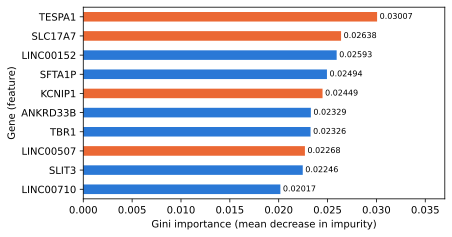

In [20]:
colors = ["#eb6834" if g in GROUND_TRUTH else "#2a78d6" for g in top10.index[::-1]]
ax = top10["Gini importance"][::-1].plot.barh(figsize=(6.4, 3.4), color=colors)
for i, v in enumerate(top10["Gini importance"][::-1]):
    ax.text(v, i, f" {v:.5f}", va="center", fontsize=8)
ax.set_xlim(0, 0.037)
ax.set_xlabel("Gini importance (mean decrease in impurity)")
ax.set_ylabel("Gene (feature)")
plt.tight_layout()
plt.show()

**Figure 2.** Gini importance (y) of the 50 highest-ranked features (x = rank) of the same best RF, showing how importance drops off. The top 10 / 50 / 100 features hold 24.36827% / 68.65741% / 85.44277% of the total importance of all 608 features; 29 features have importance above 0.01.

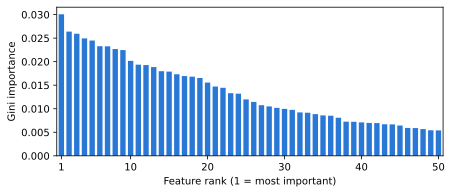

In [21]:
ax = ranking.head(50).plot.bar(figsize=(6.4, 2.8), color="#2a78d6", width=0.7)
ax.set_xticks([0, 9, 19, 29, 39, 49], labels=[1, 10, 20, 30, 40, 50], rotation=0)
ax.set_xlabel("Feature rank (1 = most important)")
ax.set_ylabel("Gini importance")
plt.tight_layout()
plt.show()

**Table 15.** Ground-truth e1 marker genes from Aevermann et al. 2018 [1]: their rank (out of 608) and Gini importance in the best RF (NTREE = 500, MTRY = 12), and their mean expression per class in the Training DB. [1] defines e1 as expressing TESPA1, LINC00507 and SLC17A7 and lacking expression of KCNIP1. None of the four genes has a duplicate column.

In [22]:
pd.DataFrame({"Rank (of 608)": [ranking.index.get_loc(g) + 1 for g in GROUND_TRUTH],
              "Gini importance": ranking[GROUND_TRUTH],
              "Mean in e1": mean_e1[GROUND_TRUTH], "Mean in non-e1": mean_non_e1[GROUND_TRUTH]})

,Rank (of 608),Gini importance,Mean in e1,Mean in non-e1
TESPA1,1,0.03007,363.25033,3.70113
LINC00507,8,0.02268,234.26795,1.72676
SLC17A7,2,0.02638,82.94761,1.04183
KCNIP1,5,0.02449,1.03098,311.03323


**Key code: accuracy using only the top-ranked features.** For each feature-set size *k*, a new RF is trained on the Training DB using only the top-*k* features from the ranking, with the best NTREE and MTRY = min(best MTRY, *k*), and its OOB accuracy is measured. A set with only the four ground-truth genes is included for reference.

In [23]:
subsets = {f"Top {k}": list(ranking.index[:k]) for k in (3, 5, 10, 20, 50, 100)}
subsets["Ground-truth genes only"] = GROUND_TRUTH
subset_rows = []
for name, cols in subsets.items():
    rf_k = RandomForestClassifier(n_estimators=best_ntree, max_features=min(best_mtry, len(cols)),
                                  oob_score=True, random_state=SEED, n_jobs=-1)
    rf_k.fit(train_df[cols].to_numpy(), y_train)
    subset_rows.append({"Feature set": name, "Features": len(cols), "OOB accuracy": rf_k.oob_score_})

**Table 16.** OOB accuracy of RFs trained on the Training DB (869 samples) using only the top-*k* ranked features, with NTREE = 500, MTRY = min(12, *k*), cutoff 0.5, `random_state=42`. For comparison, the full 608-feature best RF has an OOB accuracy of 0.99655. Because the ranking was computed on the same Training DB, small-*k* results may be slightly optimistic.

In [24]:
pd.DataFrame(subset_rows).set_index("Feature set")

,Features,OOB accuracy
Feature set,,
Top 3,3,0.98504
Top 5,5,0.98389
Top 10,10,0.98964
Top 20,20,0.99079
Top 50,50,0.99425
Top 100,100,0.99540
Ground-truth genes only,4,0.98389


### 7.2 Discussion

**Do the highly ranked features correspond to the biological knowledge?** Yes, strongly. All four genes in the paper's definition of e1 are in the RF's top 10 out of 608 genes: TESPA1 is ranked 1st, SLC17A7 2nd, KCNIP1 5th and LINC00507 8th (Table 15). The direction also matches the definition: TESPA1, SLC17A7 and LINC00507 have much higher mean expression in e1 than in other cells (e.g., TESPA1 363.25 vs 3.70), while KCNIP1 is essentially absent in e1 (1.03 vs 311.03), exactly the "lacks expression of KCNIP1" part of the definition. The other top-ranked genes also make biological sense. SLC17A7 encodes the vesicular glutamate transporter VGLUT1 and TBR1 (rank 7) is a transcription factor of cortical excitatory neurons. CUX2, the classical excitatory-neuron marker that [1] mentions, ranks 15th and 20th for its two identical columns `CUX2.1` and `CUX2`, kept separate as instructed. Since e1 is the only excitatory cell type among the 16 clusters, genes that mark excitatory neurons separate e1 from all other cells.

**How does this help explain how the RF worked?** The ranking shows that the RF decides "e1" mainly when the e1 marker genes are high (TESPA1, SLC17A7, LINC00507 and other excitatory-neuron genes) and when KCNIP1 is absent; absence of a gene is used as evidence just as much as presence. The RF reached the same marker genes from the data alone, with no biology given to it, so its decisions are based on the same signals biologists use to define the cell type rather than on some artifact of the data.

**Did this increase our confidence that the RF works well?** Yes. High accuracy (OOB 0.99655, CV 0.99540) together with features that match independent biological knowledge is much stronger evidence than accuracy alone. One caveat: [1] found these marker genes with NSforest, its own random-forest-based method, on the same study's data, so the agreement is partly a consistency check between two different RF approaches (KNIME with information gain ratio and usage counts vs. scikit-learn with Gini importance) rather than a fully independent proof. All samples also come from a single donor (Section 2.3).

**Do the ranking values show an obvious cluster of high-ranked features that dominates the ranking?** There is a clear group of high-ranked genes, but no single gene dominates. The top 10 have similar importance (0.03007 down to 0.02017) and together hold only about 24% of the total; importance then declines gradually, with 29 genes above 0.01. After about rank 50, values are below 0.0055 (Figure 2); the top 50 genes hold about 69% of all importance. The spread has a known cause: many genes are strongly correlated markers of e1, and because each split only sees MTRY = 12 random candidate genes, the trees often use a correlated substitute when TESPA1 is not among the candidates, so importance is shared across the group. Duplicated columns spread importance further: because the instructions require keeping every column separate, a gene that appears in several identical columns has its importance split between them. Summed over their copies, SLIT3 (3 columns, 0.05488) and CUX2 (2 columns, 0.03343) would rank above TESPA1 (0.03007), so the RF relies on them even more than their individual ranks show. None of the four ground-truth genes is duplicated, so their ranks are not affected.

**How many top-ranked features would we suggest for production?** Thinking as a business manager (each measured gene costs money and time), we suggest the **top 50 genes**: their RF reaches an OOB accuracy of 0.99425 (Table 16), only 0.00230 (about 2 more errors per 869 samples) below the full 608-gene model's 0.99655, while measuring 92% fewer genes, and 869 / 50 ≈ 17 samples per feature satisfies the 10× rule from the audit. If cost is critical, the **top 10 genes** give 0.98964 and the 4 ground-truth genes alone give 0.98389. These subset accuracies may be slightly optimistic because the ranking was computed on the same Training DB, so the chosen subset should be re-validated on new data before deployment.

## 8. RF Run Time test

In this section we create the RF run-time engine and use it in predict mode to classify the two samples of the Verification DB, which were never used for training.

### 8.1 Run time prediction results on verification data

**How the run-time engine was created.** The run-time engine is the retrained best RF from Section 7 (NTREE = 500, MTRY = 12, cutoff 0.5, `random_state=42`, trained on the full Training DB of 869 samples × 608 features; OOB accuracy 0.99655). It is saved to disk with `joblib` (`rf_runtime_engine.joblib`) and loaded back, as a deployed system would load it. It is then used only in predict mode: `predict()` gives the class decision (cutoff 0.5) and `predict_proba()` gives the probability of each class. In RF the probability of a class is the fraction of trees that voted for it; scikit-learn averages the trees' class probabilities, which equals the vote fraction here because fully grown trees have pure leaves.

**Key code: create the run-time engine and classify the verification samples.**

In [25]:
joblib.dump(best_rf, "rf_runtime_engine.joblib")
engine = joblib.load("rf_runtime_engine.joblib")
proba = engine.predict_proba(X_verif)          # columns: P(class 0), P(class 1)
runtime = pd.DataFrame({"True class": y_verif, "Predicted class": engine.predict(X_verif),
                        "P(class 0, non-e1)": proba[:, 0], "P(class 1, e1)": proba[:, 1]},
                       index=[f"V{i} (index {r})" for i, r in enumerate(verif_rows, start=1)])

**Table 17.** Run-time RF predictions on the Verification DB (`verification_db_e1.csv`), samples never used in training. Engine: NTREE = 500, MTRY = 12, cutoff 0.5; probabilities from `predict_proba()`.

In [26]:
runtime

,True class,Predicted class,"P(class 0, non-e1)","P(class 1, e1)"
V1 (index 26),1,1,0.04000,0.96000
V2 (index 741),0,0,0.59800,0.40200


**Table 18.** Expression of the four ground-truth marker genes in the two verification samples (compare with the class means in Table 15).

In [27]:
verif_df[GROUND_TRUTH].set_axis(runtime.index)

,TESPA1,LINC00507,SLC17A7,KCNIP1
V1 (index 26),453.40121,242.28313,30.15973,0.00000
V2 (index 741),146.20938,44.83754,29.24188,58.48375


### 8.2 Discussion

**Are the verification samples correctly classified?** Yes, both are: V1 (true class 1) is predicted as class 1 and V2 (true class 0) is predicted as class 0 (Table 17).

**Our confidence in each decision.** Confidence rests on two pieces of evidence: (1) how decisive the forest's vote is for that sample (a vote near 100% is a confident decision, a vote near 50% is uncertain); and (2) the model's estimated accuracy on unseen data: OOB accuracy 0.99655 and CV accuracy 0.99540, with e1 precision 0.99003 and recall 1.00000 (OOB).

* **V1** is classified as e1 by 480 of the 500 trees (P = 0.96000), so we are highly confident in this decision. The sample looks like a typical e1 cell (Table 18): TESPA1 (453.4), LINC00507 (242.3) and SLC17A7 (30.2) are expressed and KCNIP1 is 0, as the e1 definition requires.
* **V2** is classified correctly, but only 299 of the 500 trees vote non-e1 (P = 0.59800), so this decision is correct with **low confidence**. Table 18 shows why: V2 has an intermediate profile. It expresses TESPA1 (146.2), LINC00507 (44.8) and SLC17A7 (29.2) far above the non-e1 means but below the e1 means (Table 15), which pulls some trees toward e1. It also expresses KCNIP1 (58.5, while e1 cells average 1.03), which pulls the majority toward non-e1. The forest's final decision agrees with the paper's definition, since e1 cells must lack KCNIP1.

Two samples are a functional test of the run-time engine, not a statistical validation; the accuracy estimate comes from Methods 1 and 2. Borderline samples like V2 are rare: only 4 of the 571 non-e1 training samples have an OOB probability of e1 of 0.4 or more. In production we would therefore accept decisions with a strong vote (for example, above 0.8) automatically and send low-margin cases like V2 to an expert for review.

## 9. Use of GenAI

**GenAI tools used:** Claude (Anthropic, model Claude Opus 5.5) through Claude Code. TODO: list any other tools you used.

| Task | Prompt used | Key GenAI output | Usefulness |
|---|---|---|---|
| Understand the HW 2 requirements | "break it all down for me" (with the HW 2 instruction slides and the class recording transcript attached) | A section-by-section checklist of the required report outline, the grading table, and common pitfalls (e.g., NTREE = 100 is too low, build the OOB confusion matrix from `oob_decision_function_`, use 5 decimals, retrain the best RF before ranking) | TODO: LOW / MEDIUM / HIGH |
| Build the RF pipeline and report notebook | "Help me build the scikit-learn Jupyter notebook for HW 2 following the required report sections." | The notebook structure following the HW 2 outline; code for the NTREE × MTRY grid search with OOB, the manual stratified 3-fold CV, Gini feature ranking, the top-k experiment and the run-time engine | TODO: LOW / MEDIUM / HIGH |
| Cross-check the notebook against the course material | (attached the RF hints memo for SciKit, the scikit-learn tutorial slides, the data CSV and the research paper) | Found that the label column is named `Label`; added specificity and the confusion-matrix total check from the memo; took the data source, the single post-mortem specimen (demography), the KCNIP1 spelling and the NSforest origin of the marker genes from the paper; found the 206 duplicate columns | TODO: LOW / MEDIUM / HIGH |
| Simplify the code | "for the code itself, i think you may have gone a little overkill with the coding" and "anything that isn't neccessary to be on the file should be gone, make sure everything is good for the code" | Removed optional extras (ROC/AUC, an extra CV check, styling helpers) and moved all report text out of the code into text cells, leaving only the ML code | TODO: LOW / MEDIUM / HIGH |

**How the GenAI output was checked.** The code checks itself in two key places: the accuracy computed from each OOB confusion matrix must equal scikit-learn's `oob_score_`, and the combined CV confusion matrix must contain all 869 training samples. TODO: describe your own review of the code and results.

## 10. Resources

1. Aevermann B., Novotny M., Bakken T., Miller J., Diehl A., Osumi-Sutherland D., Lasken R., Lein E., Scheuermann R.: "Cell type discovery using single cell transcriptomics: implications for ontological representation", *Human Molecular Genetics* 27(R1): R40–R47, March 2018. (Data background and e1 ground truth.)
2. Breiman L.: "Random Forests", *Machine Learning* 45(1): 5–32, 2001.
3. Pedregosa F. et al.: "Scikit-learn: Machine Learning in Python", *Journal of Machine Learning Research* 12: 2825–2830, 2011.
4. scikit-learn documentation, `RandomForestClassifier`: https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html
5. D. Petkovic, CSC 659/859 Fall 2026: HW 2 instruction slides; "RF experiments – Useful hints for SciKit users for HW 2"; class slides on Random Forest and the ML overview (database audit checklist).
6. pandas, NumPy, matplotlib, joblib and Jupyter documentation.
7. GenAI: Claude (Anthropic), via Claude Code (see Section 9).

**People who helped:** TODO (write "None" if nobody helped).

<div style="page-break-before: always;"></div>

## Appendix: Full code

The complete code of this notebook, cell by cell (the main body shows only the key ML snippets).

In [28]:
code_cells = [c for c in json.load(open("HW2_RF_e1_cluster.ipynb"))["cells"] if c["cell_type"] == "code"]
for i, cell in enumerate(code_cells[:-1], start=1):          # all cells except this listing cell
    print(f"# ---------------- code cell {i} ----------------\n{''.join(cell['source'])}\n")

# ---------------- code cell 1 ----------------
# =============================================================================
# CSC 659/859 Fall 2026 - HW 2: ML pipeline experiment with Random Forest (RF)
# Author : Ryan Selvarajan
# Purpose: Classify e1 neuron-cluster samples (Label 1) vs. all other samples
#          (Label 0) from 608 gene-expression features with scikit-learn RF:
#          audit -> training/verification split -> RF training with OOB
#          (Method 1) and manual stratified 3-fold CV (Method 2) -> Gini feature
#          ranking -> run-time test on the 2 verification samples.
# =============================================================================
import json
import math

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix

%config InlineBackend.figure_formats = ["svg"]
pd.options.display.float_format = "{:.5f}".format   # al